# FlowRefine: CPU-only pilot and reproducible replay

**Question:** does programmatic, visual, or combined feedback improve generated flowcharts after one edit?

This notebook reads actual saved model responses. It does not fabricate missing outputs. By default, no model inference is run, no packages are installed, and no API key or GPU is needed. New CPU inference is explicitly opt-in below.

Arms: **B0** initial; **B1** programmatic feedback; **B2** visual feedback; **B3** combined. All editing arms use the same B0. The small 256M visual critic can misread diagrams; its feedback is a model output, not an evaluation label.


In [1]:
from pathlib import Path
import csv
import json
import os
import subprocess
import sys

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'GenAI_Final_Project']
ROOT = next((p for p in candidates if (p / 'src/flowrefine/cli.py').is_file() and (p / 'data/tasks.jsonl').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the FlowRefine project or its notebooks directory.')
PYTHON = ROOT / '.venv/Scripts/python.exe'
if not PYTHON.is_file():
    PYTHON = ROOT / '.venv/bin/python'
if not PYTHON.is_file():
    PYTHON = Path(sys.executable)

def cli(*arguments):
    env = os.environ.copy()
    env['PYTHONPATH'] = str(ROOT / 'src')
    command = [str(PYTHON), '-m', 'flowrefine.cli', *map(str, arguments)]
    print('Running:', ' '.join(command))
    subprocess.run(command, cwd=ROOT, env=env, check=True)

RUN = ROOT / 'runs/test_v1'
ANALYSIS = ROOT / 'analysis/test_v1'
GALLERY = ROOT / 'demo/index.html'
print('Project:', ROOT)
print('CLI interpreter:', PYTHON)
print('Saved run present:', (RUN / 'manifest.json').is_file())


Project: C:\Users\User\Desktop\учеба\GenAI_Final_Project
CLI interpreter: C:\Users\User\Desktop\учеба\GenAI_Final_Project\.venv\Scripts\python.exe
Saved run present: True


## Public tasks and evaluation boundary

The benchmark is assistant-authored and template-based: 5 development tasks, 15 held-out test tasks (5 chain, 5 branch, 5 loop), each with 6 or 7 nodes. Test topics are new; graph families repeat. This is not an experiment on general free-form human descriptions.

Generation, critics and editors use public prompts only. Reference graphs are read only by the analysis step. The scorer requires normalized exact labels and node types; synonyms can be penalized. See `data/DATASET_CARD.md` for all limitations.


In [2]:
tasks = [json.loads(line) for line in (ROOT / 'data/tasks.jsonl').read_text(encoding='utf-8').splitlines() if line.strip()]
for split in ('development', 'test'):
    selected = [t for t in tasks if t['split'] == split]
    families = {family: sum(t['family'] == family for t in selected) for family in sorted({t['family'] for t in selected})}
    print(split, 'tasks:', len(selected), 'families:', families)
print('Example public request:')
print(next(t['prompt'] for t in tasks if t['split'] == 'development'))


development tasks: 5 families: {'branch': 2, 'chain': 2, 'loop': 1}
test tasks: 15 families: {'branch': 5, 'chain': 5, 'loop': 5}
Example public request:
Create a readable directed flowchart for the following process. Use exactly the quoted stage labels. The first stage is a start node, the last is an end node, any explicitly named decision is a decision node, and all other stages are process nodes. Label decision branches exactly Yes and No. Do not add stages or connections. Follow this exact sequence: "Breakfast begins" -> "Boil water" -> "Add oats" -> "Cook porridge" -> "Serve breakfast" -> "Breakfast ready".


## Optional real CPU inference ? off by default

Keep `INFER = False` for an instant saved-results replay. With `True`, this cell can take a substantial amount of CPU time and needs the three GGUF files and `llama-cpp-python` with MTMD.

The text model is Qwen2.5-3B-Instruct Q4_K_M; the critic is SmolVLM-256M-Instruct Q8_0 with an F16 projector. They load sequentially. No image-generation service is involved. Source revisions and the installation audit are in `runtime_setup/HANDOFF.md`.

Use a new output folder when sources, settings or tasks change. Existing immutable manifests are checked by the runner; do not delete evidence to bypass a mismatch. This optional example uses development tasks, never silently tunes on the test set.


In [3]:
INFER = False
FRESH_RUN = ROOT / 'runs/notebook_cpu_v1'
if INFER:
    files = ['qwen2.5-3b-instruct-q4_k_m.gguf', 'SmolVLM-256M-Instruct-Q8_0.gguf', 'mmproj-SmolVLM-256M-Instruct-f16.gguf']
    missing = [name for name in files if not (ROOT / 'models' / name).is_file()]
    if missing:
        raise FileNotFoundError('Missing model files: ' + ', '.join(missing))
    cli('run', '--split', 'development', '--limit', '2', '--output', FRESH_RUN,
        '--model', ROOT / 'models' / files[0],
        '--vision-model', ROOT / 'models' / files[1],
        '--vision-projector', ROOT / 'models' / files[2], '--phase', 'all')
    RUN = FRESH_RUN
    ANALYSIS = ROOT / 'analysis/notebook_cpu_v1'
    GALLERY = ROOT / 'demo/notebook_cpu_v1.html'
else:
    print('Inference disabled. Replaying:', RUN)


Inference disabled. Replaying: C:\Users\User\Desktop\учеба\GenAI_Final_Project\runs\test_v1


## Recompute metrics and the offline gallery

This phase is model-free. Missing arms remain unexecuted; invalid executed outputs receive zero semantic scores, while their geometry is undefined. It is safe to inspect an incomplete run, but coverage must be reported alongside quality.


In [4]:
if (RUN / 'manifest.json').is_file():
    cli('analyze', RUN, '--output', ANALYSIS)
    cli('gallery', RUN, '--output', GALLERY)
    print('Offline gallery:', GALLERY)
else:
    print('No saved run manifest yet. No metrics or example outputs have been invented.')


Running: C:\Users\User\Desktop\учеба\GenAI_Final_Project\.venv\Scripts\python.exe -m flowrefine.cli analyze C:\Users\User\Desktop\учеба\GenAI_Final_Project\runs\test_v1 --output C:\Users\User\Desktop\учеба\GenAI_Final_Project\analysis\test_v1
Running: C:\Users\User\Desktop\учеба\GenAI_Final_Project\.venv\Scripts\python.exe -m flowrefine.cli gallery C:\Users\User\Desktop\учеба\GenAI_Final_Project\runs\test_v1 --output C:\Users\User\Desktop\учеба\GenAI_Final_Project\demo\index.html
Offline gallery: C:\Users\User\Desktop\учеба\GenAI_Final_Project\demo\index.html


In [5]:
from IPython.display import display, Markdown, Image
aggregate_path = ANALYSIS / 'aggregate.json'
if aggregate_path.is_file():
    aggregate = json.loads(aggregate_path.read_text(encoding='utf-8'))
    print('Provenance:', aggregate.get('provenance'))
    print('Tasks:', aggregate.get('task_count'))
    print('Saved calls:', aggregate.get('actual_logged_calls'))
    print('Logged model seconds:', aggregate.get('actual_logged_inference_seconds'))
    print('Reference-access flags:', aggregate.get('reference_access_violations'))
    summary = ANALYSIS / 'SUMMARY.md'
    if summary.is_file():
        display(Markdown(summary.read_text(encoding='utf-8')))
else:
    print('Summary unavailable: run inference or copy the saved experiment first.')


Provenance: real_model_inference
Tasks: 15
Saved calls: 75
Logged model seconds: 1312.8936631000033
Reference-access flags: []


# Pilot experiment summary

Tasks: 15. Provenance: real_model_inference.

| Arm | Executed / tasks | Valid | Exact semantics | Edge F1 | Geometry errors (valid only) |
|---|---:|---:|---:|---:|---:|
| B0 | 15 / 15 | 15 | 0.733 | 0.957 | 0.333 |
| B1 | 15 / 15 | 15 | 0.733 | 0.941 | 0.333 |
| B2 | 15 / 15 | 15 | 0.600 | 0.912 | 0.533 |
| B3 | 15 / 15 | 15 | 0.467 | 0.899 | 0.867 |

Actual saved calls: 75; cached: 0; logged model time: 1312.9 seconds.

Pilot on a small template-based dataset; no population-level claim.
Unexecuted arms are excluded, never assigned zero quality.
Executed invalid scenes score zero semantics; geometry is undefined.
Standalone arm costs reuse shared initial generation and visual critique costs; actual total counts each saved call once.
Intervals use 1000 task-level bootstrap resamples with a fixed seed; not corrected for multiple comparisons.
Model latency excludes local CPU validation and rendering.


## Saved initial/edit pair and actual feedback

The first available valid initial/edit pair is displayed for demonstration only, not selected as evidence of improvement. All tasks are included in the aggregate. Change `SELECT_TASK` and `SELECT_ARM` to inspect failures as well.


Program findings: []
Program findings: [{'code': 'edge_through_node', 'severity': 'error', 'affected_ids': ['e7', 'Dispatch parcel'], 'message': 'Edge e7 crosses unrelated node Dispatch parcel.'}, {'code': 'edge_through_node', 'severity': 'error', 'affected_ids': ['e8', 'Attach shipping label'], 'message': 'Edge e8 crosses unrelated node Attach shipping label.'}, {'code': 'edge_through_node', 'severity': 'error', 'affected_ids': ['e8', 'Dispatch parcel'], 'message': 'Edge e8 crosses unrelated node Dispatch parcel.'}, {'code': 'edge_label_overlap', 'severity': 'warning', 'affected_ids': ['e8', 'Attach shipping label'], 'message': 'Label of edge e8 overlaps node Attach shipping label description.'}]
Shared visual feedback:  Parcel workflow begins with Receiver parcel connected with Wrought parcel which is then connected with Attach shipping label which is further connected with Dispatch parcel. Attach shipping label is connected with both Parcel workflow complete and Print shipping label

### test_chain_01

Create a readable directed flowchart for the following process. Use exactly the quoted stage labels. The first stage is a start node, the last is an end node, any explicitly named decision is a decision node, and all other stages are process nodes. Label decision branches exactly Yes and No. Do not add stages or connections. Follow this exact sequence: "Parcel workflow begins" -> "Receive parcel" -> "Weigh parcel" -> "Print shipping label" -> "Attach shipping label" -> "Dispatch parcel" -> "Parcel workflow complete".

**B0**

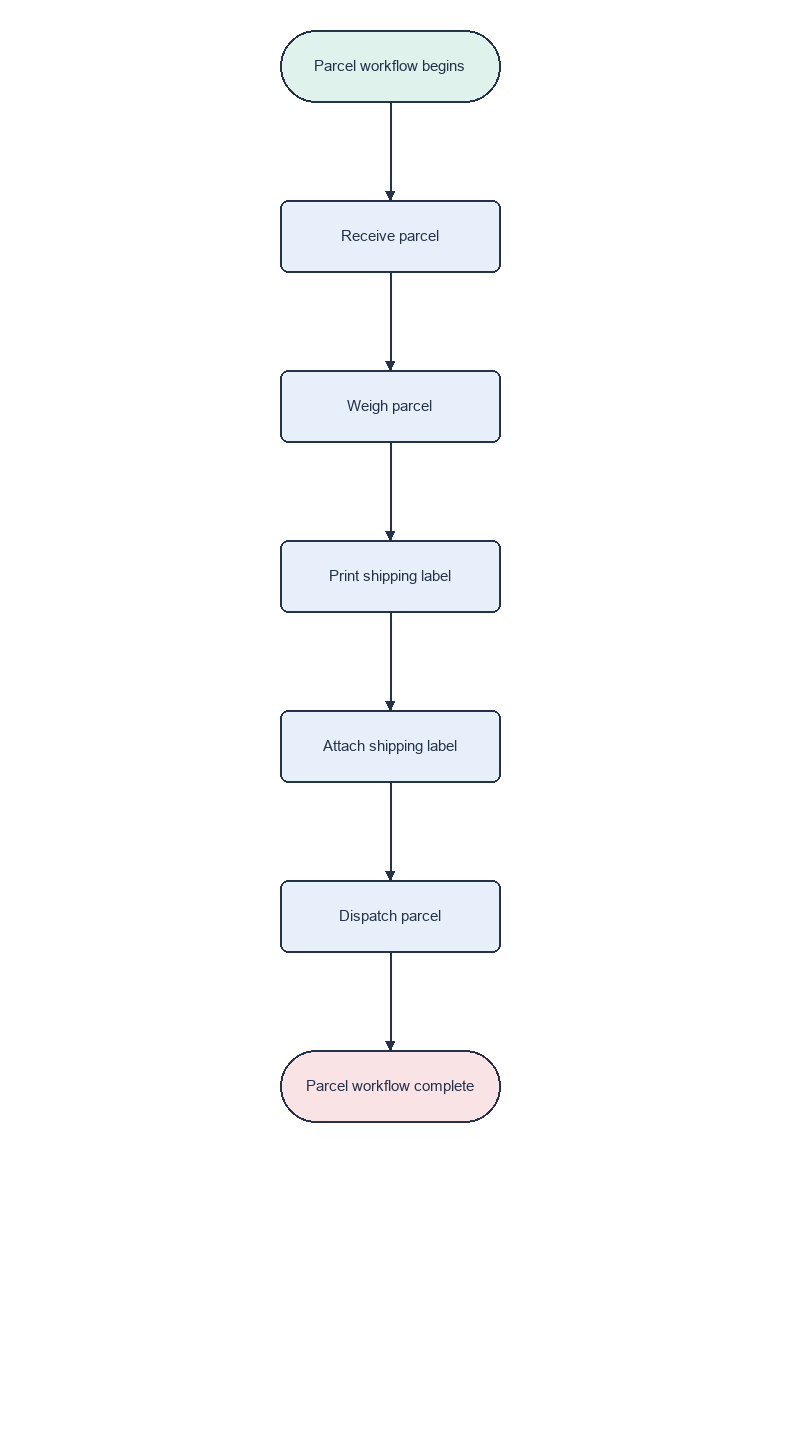

**B3**

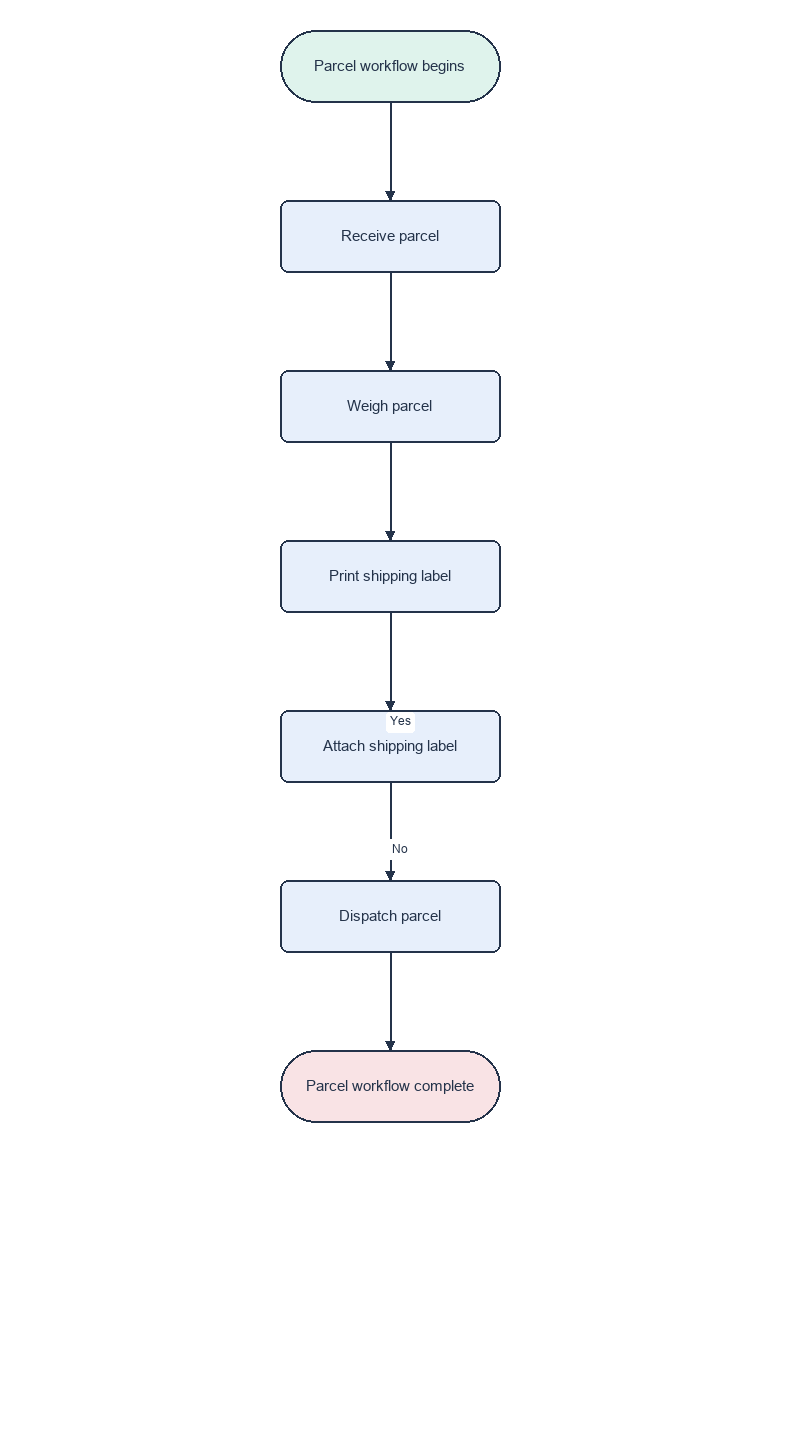

In [6]:
SELECT_TASK = None  # e.g. a task ID from runs/<run>/tasks_public.json
SELECT_ARM = 'B3'
public_path = RUN / 'tasks_public.json'
public = json.loads(public_path.read_text(encoding='utf-8')) if public_path.is_file() else []
if SELECT_TASK is None:
    SELECT_TASK = next((t['id'] for t in public if (RUN / t['id'] / 'B0/chart.png').is_file() and (RUN / t['id'] / SELECT_ARM / 'chart.png').is_file()), None)
if SELECT_TASK:
    task = next(t for t in public if t['id'] == SELECT_TASK)
    display(Markdown('### ' + SELECT_TASK + '\n\n' + task['prompt']))
    for arm in ('B0', SELECT_ARM):
        path = RUN / SELECT_TASK / arm / 'chart.png'
        display(Markdown('**' + arm + '**'))
        if path.is_file():
            display(Image(filename=str(path), width=400))
        else:
            print('Image unavailable:', path)
        feedback = RUN / SELECT_TASK / arm / 'program_feedback.json'
        if feedback.is_file():
            print('Program findings:', json.loads(feedback.read_text(encoding='utf-8')))
    visual = RUN / SELECT_TASK / 'visual/feedback.json'
    if visual.is_file():
        print('Shared visual feedback:', json.loads(visual.read_text(encoding='utf-8'))['text'])
else:
    print('No valid saved before/after pair is available yet.')


## Quality, geometry, coverage and cost

Semantic F1 uses all executed outputs, including invalid ones as zero. Geometry is compared only where valid. Standalone arm cost includes shared generation and VLM costs, while total logged calls count each call once. CPU checking/rendering time is not part of model latency.


Metric rows: 60
First row: {'task_id': 'test_chain_01', 'split': 'test', 'family': 'chain', 'arm': 'B0', 'executed': 'True', 'valid': 'True', 'reason': '', 'invalid_scene_count': '0', 'geometry_errors': '0', 'geometry_warnings': '0', 'render_available': 'True', 'render_error': '', 'standalone_calls': '1', 'standalone_cached_calls': '0', 'standalone_inference_seconds': '20.703444999999192', 'standalone_prompt_tokens': '440', 'standalone_completion_tokens': '133', 'node_precision': '1.0', 'node_recall': '1.0', 'node_f1': '1.0', 'node_tp': '7', 'node_fp': '0', 'node_fn': '0', 'node_predicted': '7', 'node_expected': '7', 'edge_precision': '1.0', 'edge_recall': '1.0', 'edge_f1': '1.0', 'edge_tp': '6', 'edge_fp': '0', 'edge_fn': '0', 'edge_predicted': '6', 'edge_expected': '6', 'exact_semantic': '1'}


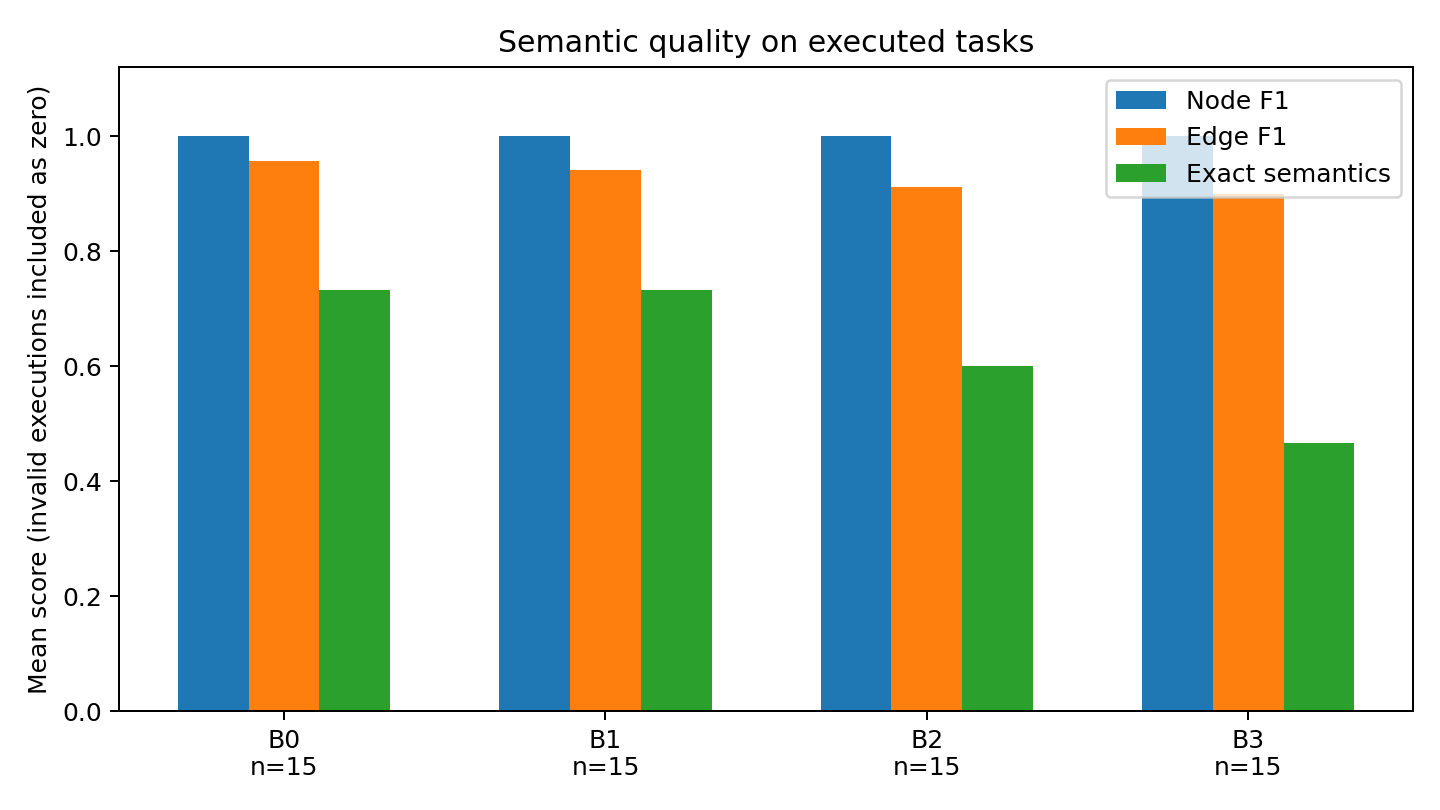

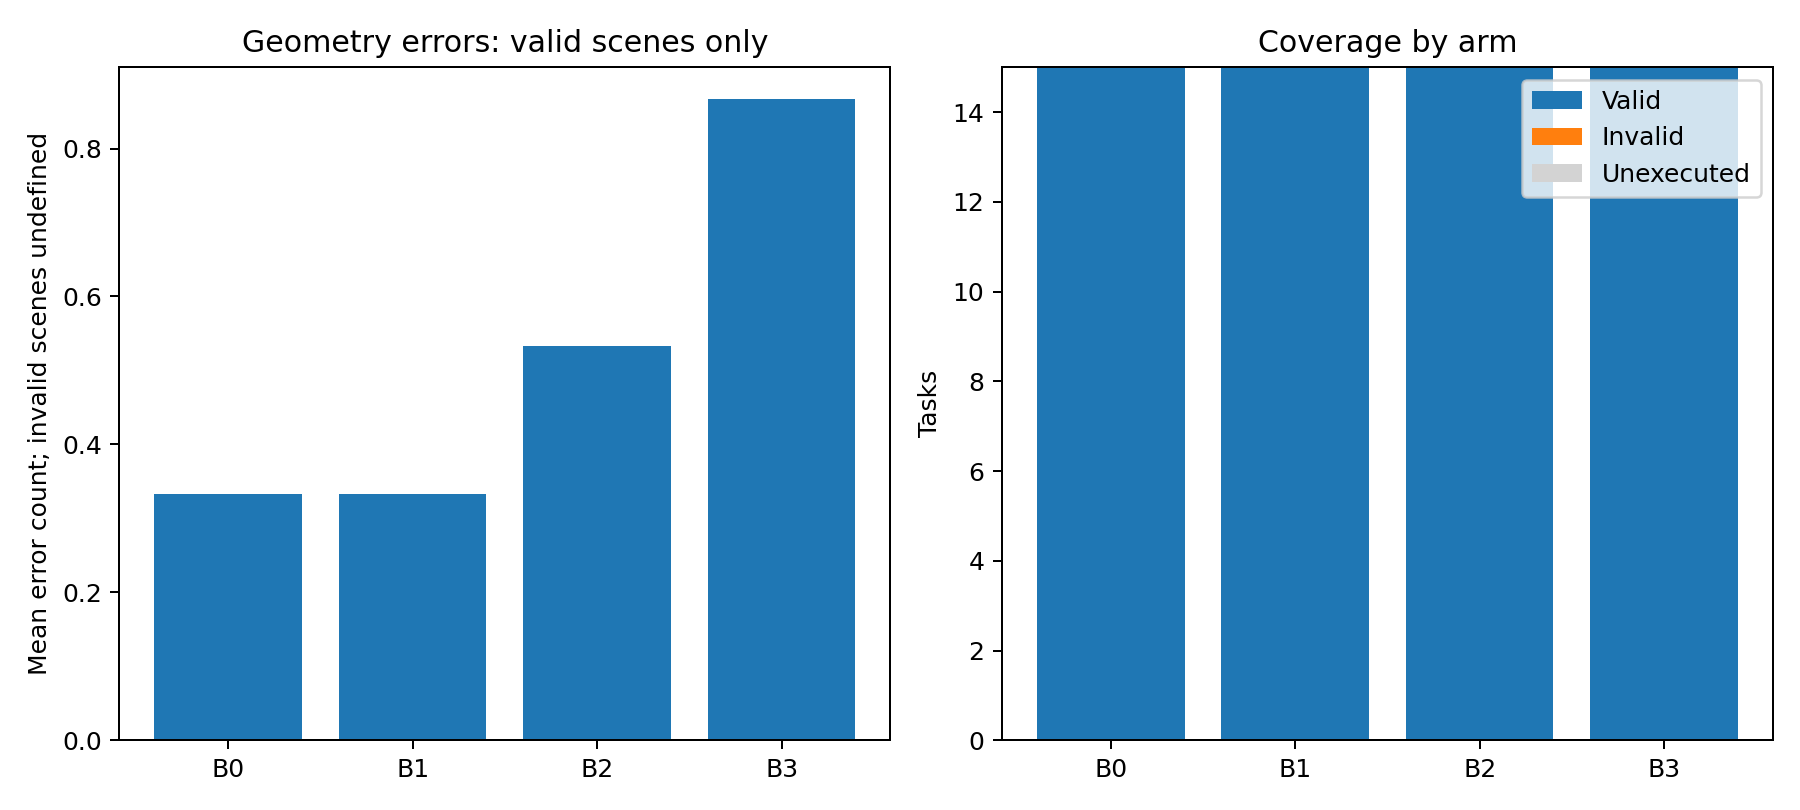

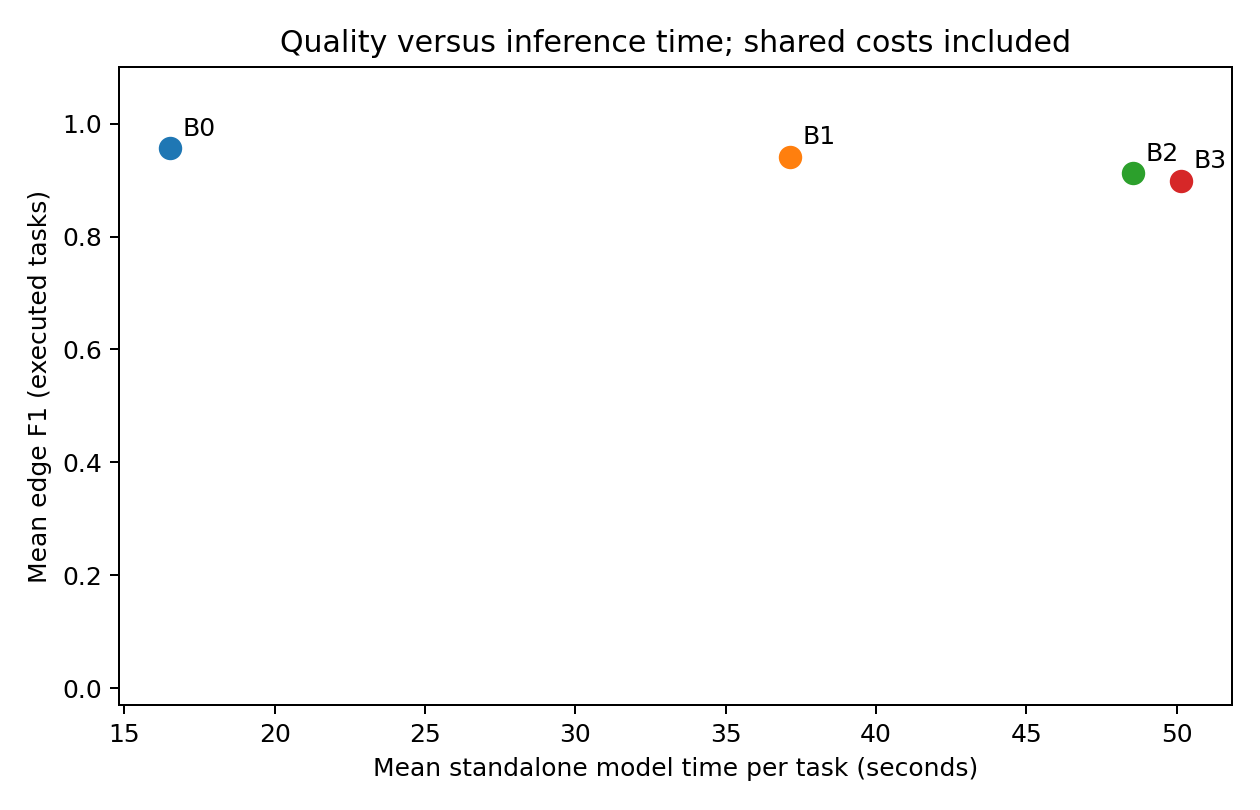

In [7]:
for name in ('semantic_quality.png', 'geometry_coverage.png', 'quality_cost.png'):
    path = ANALYSIS / name
    if path.is_file():
        display(Image(filename=str(path), width=850))
    else:
        print('Figure unavailable:', name)
metrics_path = ANALYSIS / 'metrics.csv'
if metrics_path.is_file():
    with metrics_path.open(encoding='utf-8', newline='') as handle:
        rows = list(csv.DictReader(handle))
    print('Metric rows:', len(rows))
    print('First row:', rows[0] if rows else 'none')


## What can be concluded

This is a small controlled pilot, not proof of general diagram understanding. Interpret any measured benefit together with coverage, invalid outputs, template overlap, exact-label scoring, CPU model size, and editor regressions. A weak or negative visual-critic result is a valid outcome.

There is no independent regeneration baseline, no human readability study, and no evidence that visual feedback outperforms every other use of extra compute. Review raw `call_*.json` files and manifest source hashes to audit individual claims.

For presentation, use the saved HTML viewer; for reproduction, use the commands in `README.md`. Do not label planned or missing outputs as completed experiments.
